# Portfolio construction and backtest

In [1]:
import sys
sys.path.insert(0, '../code')
import pandas as pd
from kairos import config
P = config.PATHS
pd.read_csv(P.tables / 'summary_metrics.csv', index_col=0)

,AnnReturn,AnnVol,Sharpe,Sortino,MaxDrawdown,Calmar,CVaR5,AnnTurnover,Months
BL_ML_Regime,0.073499,0.074970,0.804914,1.281101,-0.161379,0.455444,-0.041038,2.119617,211.0
BL_ML_Regime_IC,0.073686,0.070029,0.859145,1.363200,-0.131160,0.561798,-0.037526,1.323308,211.0
BL_ML_NoRegime,0.090192,0.093786,0.825081,1.331026,-0.226850,0.397582,-0.055000,1.856535,211.0
BL_ML_Raw_Regime,0.071467,0.078971,0.743849,1.144865,-0.171596,0.416486,-0.048534,4.049267,211.0
BL_HistMean_Regime,0.079595,0.073826,0.893913,1.457713,-0.153128,0.519792,-0.038948,1.342525,211.0
Market_Reference,0.103939,0.097418,0.926883,1.519080,-0.210603,0.493530,-0.055646,0.345936,211.0
Equal_Weight,0.094899,0.112512,0.743854,1.299958,-0.235862,0.402351,-0.058937,0.540171,211.0
Static_60_40,0.103733,0.091176,0.980462,1.595831,-0.205222,0.505469,-0.051941,0.265035,211.0
Inverse_Vol,0.066374,0.071303,0.748663,1.185394,-0.177275,0.374415,-0.041878,0.461058,211.0
MeanVariance_LW,0.059977,0.132818,0.402221,0.616532,-0.369744,0.162211,-0.081104,2.524840,211.0


In [2]:
pd.read_csv(P.tables / 'significance.csv')

,strategy,benchmark,diff,ci_low,ci_high,p_value,n
0,BL_ML_Regime,BL_ML_Regime_IC,-0.054231,-0.178652,0.066604,0.387403,211
1,BL_ML_Regime,BL_ML_NoRegime,-0.020167,-0.149972,0.098609,0.761810,211
2,BL_ML_Regime,BL_ML_Raw_Regime,0.061065,-0.103319,0.220675,0.464634,211
3,BL_ML_Regime,BL_HistMean_Regime,-0.088999,-0.149181,-0.039353,0.002749,211
4,BL_ML_Regime,Market_Reference,-0.121969,-0.308700,0.040291,0.174956,211
5,BL_ML_Regime,Equal_Weight,0.061060,-0.154529,0.301693,0.591102,211
6,BL_ML_Regime,Static_60_40,-0.175548,-0.426828,0.029763,0.134716,211
7,BL_ML_Regime,Inverse_Vol,0.056251,-0.197920,0.270061,0.630342,211
8,BL_ML_Regime,MeanVariance_LW,0.402693,0.102456,0.711608,0.012247,211
9,BL_ML_Regime,Regime_60_40,-0.174875,-0.411941,0.031289,0.122969,211


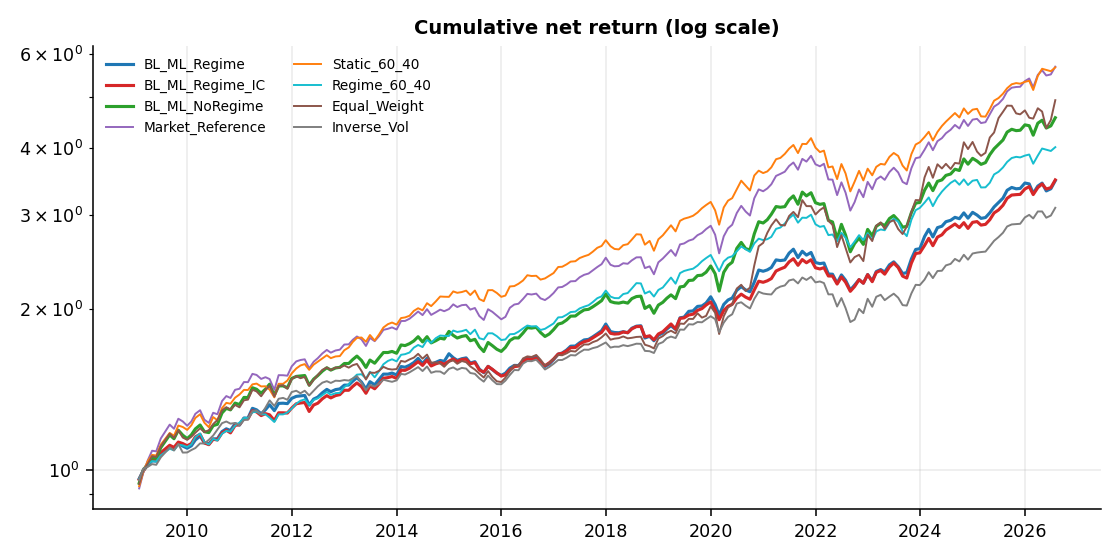

In [3]:
from IPython.display import Image
Image(str(P.figures / '07_cumulative_returns.png'))

In [4]:
pd.read_csv(P.tables / 'regime_metrics.csv', index_col=[0, 1])

AnnReturn    AnnVol    Sharpe   Sortino  \
BL_ML_Regime       All        0.073499  0.074970  0.804914  1.281101   
                   Calm       0.067116  0.075891  0.695989  1.105876   
                   Stressed   0.086755  0.073461  1.031716  1.655774   
BL_ML_Regime_IC    All        0.073686  0.070029  0.859145  1.363200   
                   Calm       0.066398  0.070339  0.735695  1.147155   
                   Stressed   0.088841  0.069720  1.111045  1.838097   
BL_ML_NoRegime     All        0.090192  0.093786  0.825081  1.331026   
                   Calm       0.067655  0.075880  0.702795  1.118606   
                   Stressed   0.138079  0.122287  1.039320  1.687056   
BL_ML_Raw_Regime   All        0.071467  0.078971  0.743849  1.144865   
                   Calm       0.071339  0.082793  0.692696  1.075142   
                   Stressed   0.071730  0.071034  0.865870  1.313100   
BL_HistMean_Regime All        0.079595  0.073826  0.893913  1.457713   
                   Calm       0.073200  0.074377  0.786033  1.277304   
                   Stressed   0.092876  0.073092  1.114721  1.839798   
Market_Reference   All        0.103939  0.097418  0.926883  1.519080   
                   Calm       0.075984  0.074823  0.816134  1.288680   
                   Stressed   0.163775  0.131488  1.146670  1.913965   
Equal_Weight       All        0.094899  0.112512  0.743854  1.299958   
                   Calm       0.057008  0.094981  0.471497  0.806763   
                   Stressed   0.177207  0.140178  1.169160  2.055228   
Static_60_40       All        0.103733  0.091176  0.980462  1.595831   
                   Calm       0.080392  0.070113  0.922228  1.435876   
                   Stressed   0.153368  0.123258  1.140569  1.906032   
Inverse_Vol        All        0.066374  0.071303  0.748663  1.185394   
                   Calm       0.055294  0.060090  0.674895  1.087121   
                   Stressed   0.089546  0.090259  0.885495  1.381842   
MeanVariance_LW    All        0.059977  0.132818  0.402221  0.616532   
                   Calm       0.038848  0.114899  0.255875  0.366346   
                   Stressed   0.104822  0.163822  0.627872  1.042592   
Regime_60_40       All        0.082348  0.069463  0.979789  1.551506   
                   Calm       0.079598  0.070123  0.911538  1.415967   
                   Stressed   0.088031  0.068567  1.117040  1.861110   
Regime_Market      All        0.081244  0.074160  0.910349  1.456206   
                   Calm       0.075202  0.074840  0.806140  1.269599   
                   Stressed   0.093785  0.073171  1.124443  1.872131   

                             MaxDrawdown    Calmar     CVaR5  AnnTurnover  \
BL_ML_Regime       All         -0.161379  0.455444 -0.041038     2.119617   
                   Calm        -0.116771  0.574771 -0.038614     2.104292   
                   Stressed    -0.111735  0.776437 -0.042490     2.151155   
BL_ML_Regime_IC    All         -0.131160  0.561798 -0.037526     1.323308   
                   Calm        -0.101796  0.652263 -0.036094     1.100008   
                   Stressed    -0.097148  0.914494 -0.038900     1.782852   
BL_ML_NoRegime     All         -0.226850  0.397582 -0.055000     1.856535   
                   Calm        -0.115930  0.583586 -0.038571     1.598074   
                   Stressed    -0.190500  0.724826 -0.070462     2.388439   
BL_ML_Raw_Regime   All         -0.171596  0.416486 -0.048534     4.049267   
                   Calm        -0.113092  0.630807 -0.047621     4.390177   
                   Stressed    -0.114822  0.624706 -0.046622     3.347685   
BL_HistMean_Regime All         -0.153128  0.519792 -0.038948     1.342525   
                   Calm        -0.109076  0.671089 -0.036517     1.149277   
                   Stressed    -0.109151  0.850894 -0.040609     1.740224   
Market_Reference   All         -0.210603  0.493530 -0.055646     0.345936   
                   Calm        -0.105625  0.719375 -0.0

In [5]:
pd.read_csv(P.tables / 'cost_sensitivity.csv', index_col=0)

,0bps,10bps,25bps,50bps
BL_ML_Regime,0.834089,0.804914,0.761158,0.688298
BL_ML_Regime_IC,0.878862,0.859145,0.829535,0.780125
BL_ML_NoRegime,0.845929,0.825081,0.793840,0.741879
BL_ML_Raw_Regime,0.794962,0.743849,0.666974,0.538431
BL_HistMean_Regime,0.912742,0.893913,0.865634,0.818432
Market_Reference,0.930855,0.926883,0.920921,0.910976
Equal_Weight,0.748848,0.743854,0.736358,0.723855
Static_60_40,0.983801,0.980462,0.975448,0.967074
Inverse_Vol,0.755557,0.748663,0.738318,0.721066
MeanVariance_LW,0.421113,0.402221,0.373841,0.326436
